# 06 — Cameroon boundary and spatial scope audit

This notebook compares normalized FIRMS coordinates with a pinned geoBoundaries Cameroon ADM0 geometry. It reports inside/outside counts; it does not infer FIRMS coverage completeness or validate detections. Boundary is contextual only.

Boundary source metadata: geoBoundaries, CMR ADM0, represented year 2016, ID `CMR-ADM0-59405334`, source `geoBoundaries, Wikimedia`, boundaryLicense `CC BY 3.0`. Attribution is required. GeoJSON SHA-256: `2688A0D9B15237A71E2620222F963BA5D00F06D7376F0497B807605DF2D5B1A3`.


In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path as PolygonPath

ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT.parent / 'data').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'data' / 'processed' / 'observations.parquet'
BOUNDARY = ROOT / 'data' / 'reference' / 'geoBoundaries-CMR-ADM0-2016.geojson'
assert DATA.is_file(), f'Missing normalized observations: {DATA}'
assert BOUNDARY.is_file(), f'Missing pinned boundary file: {BOUNDARY}'
digest = hashlib.sha256(BOUNDARY.read_bytes()).hexdigest().upper()
assert digest == '2688A0D9B15237A71E2620222F963BA5D00F06D7376F0497B807605DF2D5B1A3', digest
print('Boundary SHA-256 verified:', digest)


Boundary SHA-256 verified: 2688A0D9B15237A71E2620222F963BA5D00F06D7376F0497B807605DF2D5B1A3


In [2]:
geo = json.loads(BOUNDARY.read_text(encoding='utf-8'))
geom = geo['features'][0]['geometry']
polygons = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
obs = pd.read_parquet(DATA, columns=['observation_id','latitude_num','longitude_num','year_folder','product_code','satellite','stream_type'])
coords = obs[['longitude_num','latitude_num']].to_numpy(dtype=float)
inside = np.zeros(len(coords), dtype=bool)
for rings in polygons:
    in_outer = PolygonPath(np.asarray(rings[0], dtype=float)).contains_points(coords)
    for hole in rings[1:]:
        in_outer &= ~PolygonPath(np.asarray(hole, dtype=float)).contains_points(coords)
    inside |= in_outer
obs['spatial_scope'] = np.where(inside, 'inside', 'outside')
print(f'{len(obs):,} total; {inside.sum():,} inside ({inside.mean():.4%}); {(~inside).sum():,} outside')


1,130,027 total; 1,122,291 inside (99.3154%); 7,736 outside


In [3]:
scope_by_source = (obs.groupby(['year_folder','product_code','satellite','stream_type','spatial_scope'])
                  .size().rename('records').reset_index())
display(scope_by_source)


,year_folder,product_code,satellite,stream_type,spatial_scope,records
0,2025,J1V-C2,N20,archive,inside,223046
1,2025,J1V-C2,N20,archive,outside,1560
2,2025,J2V-C2,N21,archive,inside,216766
3,2025,J2V-C2,N21,archive,outside,1422
4,2025,M-C61,Aqua,archive,inside,35733
5,2025,M-C61,Aqua,archive,outside,167
6,2025,M-C61,Terra,archive,inside,6153
7,2025,M-C61,Terra,archive,outside,67
8,2025,SV-C2,SNPP,archive,inside,225786
9,2025,SV-C2,SNPP,archive,outside,1534


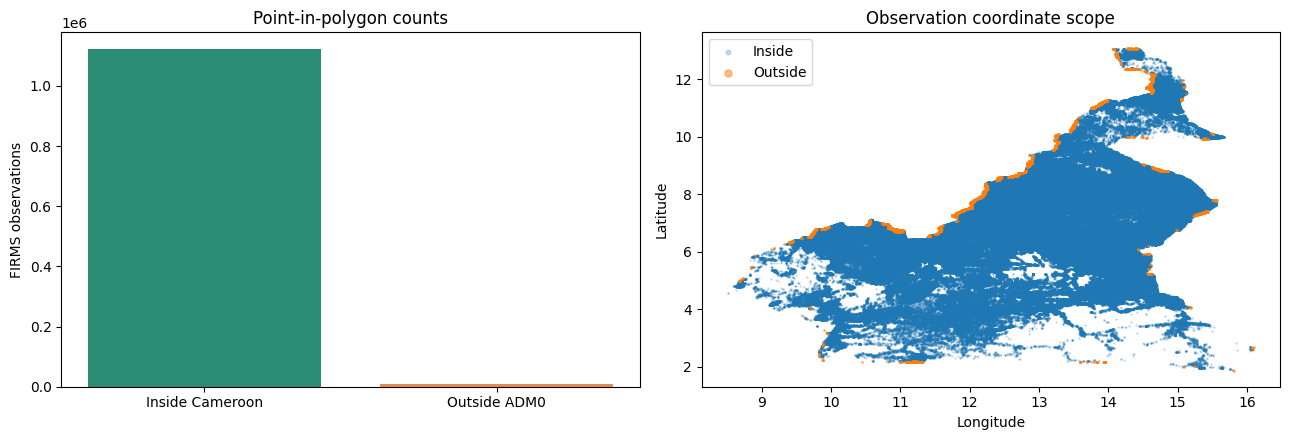

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(['Inside Cameroon','Outside ADM0'], [inside.sum(), (~inside).sum()], color=['#2b8c76','#e78b50'])
axes[0].set_ylabel('FIRMS observations'); axes[0].set_title('Point-in-polygon counts')
axes[1].scatter(obs.loc[inside,'longitude_num'], obs.loc[inside,'latitude_num'], s=0.4, alpha=.25, label='Inside')
axes[1].scatter(obs.loc[~inside,'longitude_num'], obs.loc[~inside,'latitude_num'], s=1.0, alpha=.5, label='Outside')
axes[1].set_xlabel('Longitude'); axes[1].set_ylabel('Latitude'); axes[1].set_title('Observation coordinate scope'); axes[1].legend(markerscale=5)
plt.tight_layout(); plt.show()


## Interpretation and limitations

Points outside the ADM0 polygon are retained in source and normalized records. Their presence across instruments is consistent with extracts that include a regional bounding area around Cameroon. It does not prove the intended FIRMS request extent, data completeness, active-fire truth, or national coverage. Do not convert inside/outside counts into fire prevalence. Boundary-edge inclusion behavior is governed by the plotting path implementation; points exactly on a border should be treated as an edge case.
